# Explainable AI: why does the model predict heat where it does?

Member 4, step 1 (slides 21, 24; CONTRACTS section 4). Models from the hand-overs:
- **student** `m3_lite16_kd`: Member 3's recommended small model (R² 0.784), fed with `distill.Prepared` (indices clipped).
- **teacher** `cnn_robust_fusion_cnn_s0`: Member 2's fusion CNN that Member 3 distilled, fed with the plain `PatchDataset`.

**Method** (`urbanheat.explain.xai`):
- **Integrated gradients (IG)**, the Aumann–Shapley value along the path from a baseline input to the scene
  (SHAP for a smooth model). Baseline = all-zero normalised input = the train mean (city median for thermal context
  and elevation). Target = the summed predicted anomaly over the city, so attributions are in **°C** and add up to
  prediction − baseline prediction (checked below).
- Attributions are summed into 9 **input groups** (hyperspectral, Landsat bands, NDVI, NDBI, MNDWI, elevation,
  slope, built share, thermal context). `direction` = slope of the attribution on the normalised input through the
  baseline (the x²-weighted mean path gradient, °C per +1 std at a pixel): **> 0 means a higher value makes the area
  hotter**. (A centred correlation was tried first; it mixes in the spatial pattern and flipped the NDVI sign.)
- **Grad-CAM** per branch (surface, thermal) for the mean prediction of the hottest 10 % of pixels: which places each
  branch relied on.

All 56 test cities (never seen in training).

In [1]:
import time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, h5py
from pathlib import Path
from urbanheat.config import load_config
from urbanheat.data.dataset import PatchDataset
from urbanheat.efficient import lite
from urbanheat.efficient.distill import Prepared
from urbanheat.explain import xai
from urbanheat.models import train
from urbanheat.contracts import Scenario
from urbanheat.scenarios import engine
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90
cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])                          # Member 2's runs (outside git)
REPO_RUNS = Path("../../runs")                         # Member 3's runs (in git)
DEV = "cuda" if torch.cuda.is_available() else "cpu"

ds_plain = PatchDataset(H5, "test")
ds_prep = Prepared(ds_plain)
models = {"student m3_lite16_kd": (lite.load(REPO_RUNS / "m3_lite16_kd", DEV), ds_prep),
          "teacher fusion_cnn": (lite.load(RUNS / "cnn_robust_fusion_cnn_s0", DEV), ds_plain)}
with h5py.File(H5) as f:
    info = {p: dict(climate_group=f["pairs"][p].attrs["climate_group"]) for p in ds_plain.pairs}
print(len(ds_plain.pairs), "test cities on", DEV, "| climates:", pd.Series([i["climate_group"] for i in info.values()]).value_counts().to_dict())

56 test cities on cuda | climates: {'tropical': 41, 'arid': 8, 'temperate': 6, 'cold': 1}


## Check: attributions add up to the prediction (completeness)

In [2]:
pid = "EMIT_243"
for name, (m, d) in models.items():
    s = d.scene(pid)
    attr = xai.integrated_gradients(m, s, DEV, steps=64)
    pred = train.predict_scene(m, d, pid, DEV)[0][s["mask"]].sum()
    total = sum(a.sum() for a in attr.values())
    print(f"{name:22s} sum(IG) = {total:9.1f}   pred - baseline = {pred - xai.baseline_sum(m, s, DEV):9.1f}  (deg C x pixels)")

student m3_lite16_kd   sum(IG) =    -176.6   pred - baseline =    -162.6  (deg C x pixels)


teacher fusion_cnn     sum(IG) =   -2194.3   pred - baseline =   -2197.4  (deg C x pixels)


## Global importance: which inputs move the prediction, per climate

In [3]:
tables, maps = {}, {}
for name, (m, d) in models.items():
    t0 = time.time()
    tables[name], maps[name] = xai.global_importance(m, d, info, DEV, steps=32)
    print(f"{name}: {time.time() - t0:.0f} s")
out = REPO_RUNS / "m3_lite16_kd" / "explain"
out.mkdir(parents=True, exist_ok=True)
tables["student m3_lite16_kd"].to_csv(out / "global_importance.csv", index=False)
(RUNS / "cnn_robust_fusion_cnn_s0" / "explain").mkdir(exist_ok=True)
tables["teacher fusion_cnn"].to_csv(RUNS / "cnn_robust_fusion_cnn_s0" / "explain" / "global_importance.csv", index=False)
st = tables["student m3_lite16_kd"]
st.pivot(index="feature", columns="climate_group", values="mean_abs_shap").sort_values("all", ascending=False).round(3)

student m3_lite16_kd: 10 s


teacher fusion_cnn: 24 s


climate_group,all,arid,cold,temperate,tropical
feature,,,,,
thermal context,1.779,2.029,1.516,2.331,1.679
hyperspectral,0.234,0.218,0.134,0.213,0.240
landsat bands,0.179,0.251,0.119,0.170,0.170
built_share,0.168,0.201,0.086,0.157,0.165
NDBI,0.099,0.127,0.048,0.083,0.097
NDVI,0.064,0.096,0.036,0.054,0.061
MNDWI,0.055,0.078,0.033,0.035,0.054
slope,0.044,0.030,0.037,0.023,0.049
elevation,0.012,0.004,0.013,0.004,0.014


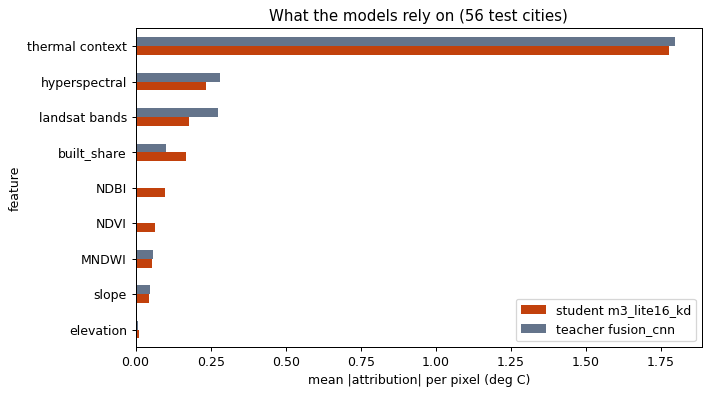

share of total attribution (%):
                 student m3_lite16_kd  teacher fusion_cnn
feature                                                  
thermal context                  67.5                69.9
hyperspectral                     8.9                10.9
landsat bands                     6.8                10.7
built_share                       6.4                 4.0
NDBI                              3.8                 0.1
NDVI                              2.4                 0.1
MNDWI                             2.1                 2.2
slope                             1.7                 1.9
elevation                         0.4                 0.3


In [4]:
both = pd.concat({k: t[t.climate_group == "all"].set_index("feature")["mean_abs_shap"] for k, t in tables.items()}, axis=1)
both = both.sort_values("student m3_lite16_kd")
ax = both.plot.barh(figsize=(8, 4.5), color=["#c2410c", "#64748b"])
ax.set_xlabel("mean |attribution| per pixel (deg C)"); ax.set_title("What the models rely on (56 test cities)")
plt.tight_layout(); plt.show()
share = both / both.sum()
print("share of total attribution (%):"); print((100 * share).round(1).sort_values("student m3_lite16_kd", ascending=False))
comp = pd.concat({k: t[t.climate_group == "all"].set_index("feature")[["mean_abs_shap", "direction"]]
                  .assign(share_pct=lambda d: 100 * d.mean_abs_shap / d.mean_abs_shap.sum()) for k, t in tables.items()},
                 names=["model"]).reset_index()
comp.to_csv(out / "comparison.csv", index=False)          # for the dashboard's insights panel

## Direction: does the model respond the physical way?

Expected: NDVI and MNDWI negative (greener / wetter → cooler), NDBI and built share positive (more built-up → hotter).
Member 3 reported that the student follows NDVI and NDBI in the right direction and the teacher barely responds.

In [5]:
dirs = pd.concat({k: t[t.climate_group == "all"].set_index("feature")["direction"] for k, t in tables.items()}, axis=1)
expected = {"NDVI": "-", "NDBI": "+", "MNDWI": "-", "built_share": "+", "thermal context": "+", "elevation": "-"}
dirs = dirs.loc[list(expected)].assign(expected=list(expected.values()))
dirs.round(2)

,student m3_lite16_kd,teacher fusion_cnn,expected
feature,,,
NDVI,0.03,-0.02,-
NDBI,-0.02,0.01,+
MNDWI,-0.02,-0.06,-
built_share,0.02,-0.07,+
thermal context,5.96,6.05,+
elevation,-0.03,-0.10,-


In [6]:
st_dir = st[st.feature.isin(["NDVI", "NDBI", "built_share", "MNDWI"])].pivot(index="climate_group", columns="feature", values="direction")
st_dir.round(2)

feature,MNDWI,NDBI,NDVI,built_share
climate_group,,,,
all,-0.02,-0.02,0.03,0.02
arid,-0.05,0.10,-0.05,-0.16
cold,0.02,0.00,0.01,-0.10
temperate,0.01,-0.01,0.01,-0.02
tropical,-0.02,-0.04,0.04,0.05


## The `densify` scenario cools: why?

Member 3's `densify` map (built share +0.1 only) has mostly negative ΔLST. Below: the same scenario on the central
32 × 32 block of every test city, compared with the student's IG direction for built share.

In [7]:
def centre(shape, size=32):
    m = np.zeros(shape, bool); r, c = (shape[0] - size) // 2, (shape[1] - size) // 2
    m[max(r, 0):r + size, max(c, 0):c + size] = True
    return m

rows = []
for name, (m, d) in models.items():
    for sc in [Scenario("densify", {"built_share": 0.1}), Scenario("ndvi_only", {"NDVI": 0.1}),
               Scenario("ndbi_only", {"NDBI": 0.1})]:
        vals = []
        for p in d.pairs:
            s = d.scene(p)
            w = centre(s["mask"].shape) & s["mask"]
            if w.sum() > 50:
                vals.append(np.nanmean(engine.delta_lst(m, d, p, sc, DEV, where=w)[w]))
        rows.append(dict(model=name, scenario=sc.name, change=str(sc.changes), mean_dlst_c=np.mean(vals),
                         cities_cooling=np.mean(np.array(vals) < 0)))
resp = pd.DataFrame(rows)
resp.to_csv(out / "response_tests.csv", index=False)   # for the dashboard
resp.round(3)

,model,scenario,change,mean_dlst_c,cities_cooling
0,student m3_lite16_kd,densify,{'built_share': 0.1},0.006,0.643
1,student m3_lite16_kd,ndvi_only,{'NDVI': 0.1},-0.017,0.696
2,student m3_lite16_kd,ndbi_only,{'NDBI': 0.1},0.071,0.143
3,teacher fusion_cnn,densify,{'built_share': 0.1},-0.020,0.536
4,teacher fusion_cnn,ndvi_only,{'NDVI': 0.1},-0.001,0.964
5,teacher fusion_cnn,ndbi_only,{'NDBI': 0.1},0.002,0.036


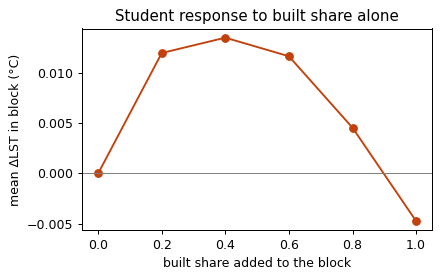

[ 0.     0.012  0.013  0.012  0.005 -0.005]


In [8]:
# built share response curve of the student: mean predicted anomaly of the central block vs built share set to a value
m, d = models["student m3_lite16_kd"]
levels, curve = np.linspace(0, 1, 6), []
for p in d.pairs:
    s = d.scene(p); w = centre(s["mask"].shape) & s["mask"]
    if w.sum() <= 50: continue
    std, mean = d.norm["env_std"][2], d.norm["env_mean"][2]
    raw = s["env"][2] * std + mean
    curve.append([np.nanmean(engine.delta_lst(m, d, p, Scenario("set", {"built_share": float(v)}), DEV, where=w)[w])
                  for v in levels])          # additive change v from current (clipped to [0, 1])
curve = np.array(curve)
plt.figure(figsize=(5, 3.2)); plt.plot(levels, curve.mean(0), "o-", color="#c2410c")
plt.axhline(0, color="grey", lw=0.8); plt.xlabel("built share added to the block"); plt.ylabel("mean ΔLST in block (°C)")
plt.title("Student response to built share alone"); plt.tight_layout(); plt.show()
print(np.round(curve.mean(0), 3))

## One city: where the heat comes from (EMIT_243)

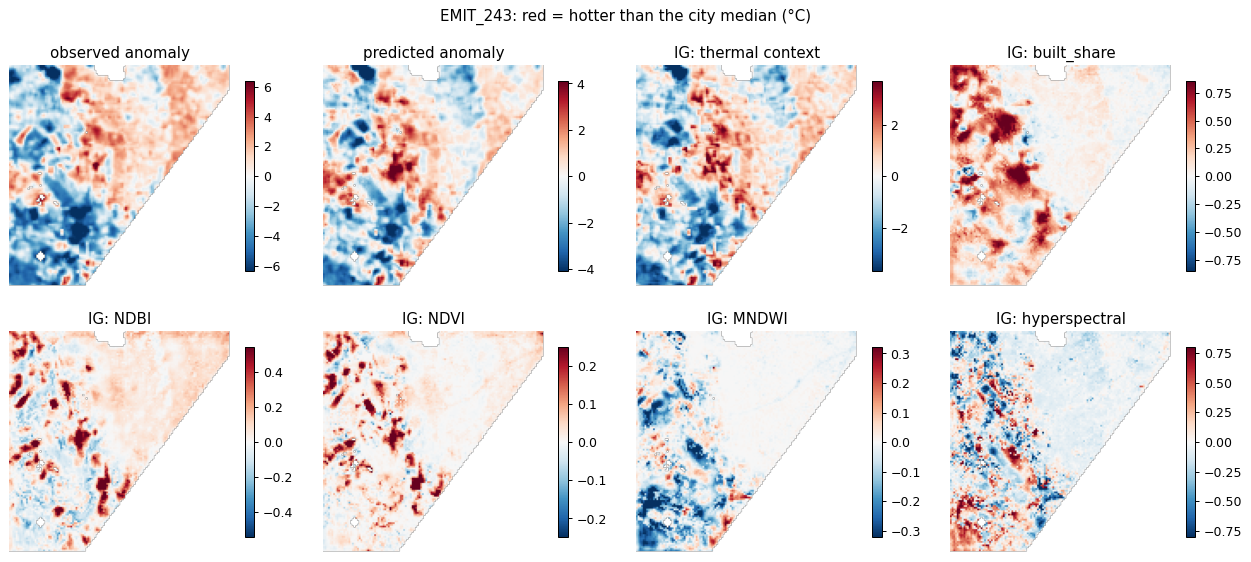

wrote ..\..\runs\m3_lite16_kd\explain\EMIT_243_attr.tif


In [9]:
m, d = models["student m3_lite16_kd"]
s = d.scene(pid); med = float(h5py.File(H5)["pairs"][pid].attrs["lst_median_c"])
pred = train.predict_scene(m, d, pid, DEV)[0]
g = maps["student m3_lite16_kd"][pid]
show = {"observed anomaly": s["y"], "predicted anomaly": pred, **{f"IG: {k}": g[k] for k in
        ["thermal context", "built_share", "NDBI", "NDVI", "MNDWI", "hyperspectral"]}}
fig, axs = plt.subplots(2, 4, figsize=(14, 6.6))
for ax, (k, a) in zip(axs.flat, show.items()):
    v = np.where(s["mask"], a, np.nan); lim = np.nanpercentile(np.abs(v), 98)
    im = ax.imshow(v, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.set_title(k); ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.7)
plt.suptitle(f"{pid}: red = hotter than the city median (°C)"); plt.tight_layout(); plt.show()
p = xai.write_bands(REPO_RUNS / "m3_lite16_kd" / "explain" / f"{pid}_attr.tif", g, H5, pid, mask=s["mask"], note=xai.CAVEAT,
                    method="integrated gradients, 32 steps, zero (train-mean) baseline", model="m3_lite16_kd")
print("wrote", p)

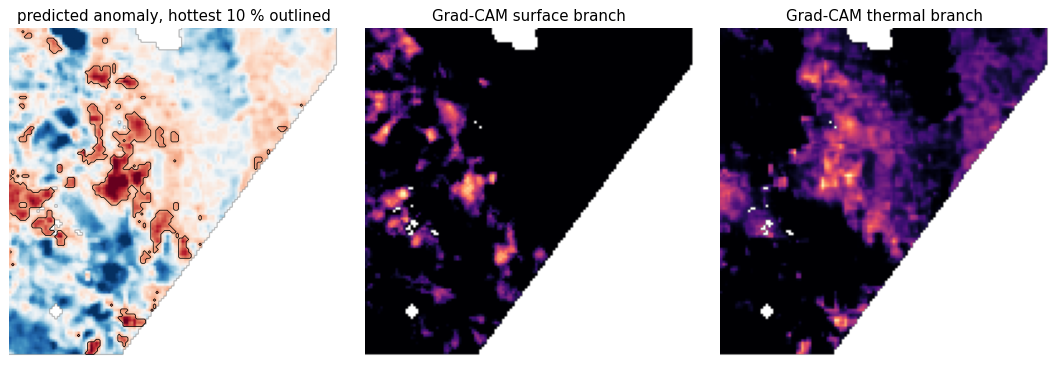

surface: share of Grad-CAM mass inside the hottest 10 %: 45%
thermal: share of Grad-CAM mass inside the hottest 10 %: 33%


In [10]:
cam = xai.grad_cam(m, s, device=DEV)
hot = s["mask"] & (pred >= np.quantile(pred[s["mask"]], 0.9))
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
lim = np.percentile(np.abs(pred[s["mask"]]), 98)
axs[0].imshow(np.where(s["mask"], pred, np.nan), cmap="RdBu_r", vmin=-lim, vmax=lim); axs[0].contour(hot, levels=[0.5], colors="k", linewidths=0.6)
axs[0].set_title("predicted anomaly, hottest 10 % outlined")
for ax, (b, c) in zip(axs[1:], cam.items()):
    ax.imshow(np.where(s["mask"], c, np.nan), cmap="magma", vmin=0, vmax=1); ax.set_title(f"Grad-CAM {b} branch")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()
for b, c in cam.items():
    print(f"{b}: share of Grad-CAM mass inside the hottest 10 %: {c[hot].sum() / c[s['mask']].sum():.0%}")

## What this shows

1. **The explanations are exact accounts of the prediction.** Attributions add up to prediction − baseline (teacher
   within 0.2 %; student within 14 °C·px over 11,623 px, i.e. 0.001 °C per pixel).
2. **Both models are mostly a thermal-context model.** Thermal context (other dates' LST) carries 68 % (student) and
   70 % (teacher) of all attribution. Among surface inputs, the hyperspectral bands (9–11 %), Landsat bands (7–11 %)
   and built share (4–6 %) matter most. The student uses the indices far more than the teacher (NDBI 3.8 % vs
   0.1 %, NDVI 2.4 % vs 0.1 %): Member 3's index clipping made them usable, and the teacher, trained on
   outlier-inflated statistics, barely sees them.
3. **The response to one factor alone is small, and its sign is not stable.** Per pixel, a 1-std change of NDVI,
   NDBI or built share moves the predictions around it by only ±0.02–0.07 °C (thermal context: 6 °C), and the sign
   changes between climates. In the block test the student shows one clear physical response, **NDBI +0.1 → +0.07 °C
   (warmer in 86 % of cities)**. NDVI +0.1 gives −0.02 °C (cooler in 70 %). The teacher responds to neither,
   which confirms Member 3's finding.
4. **The cooling `densify` map is noise around zero.** Built share +0.1 alone changes the student's block by
   +0.006 °C on average (64 % of cities slightly cooler), and adding up to +1 stays within ±0.015 °C. The model uses
   built share as a spatial *pattern* (6 % of attribution) but has not learned a *level* effect. Show `densify` in
   the dashboard as "no measurable effect", not as cooling. The coupled presets (built → green, green → built)
   get their sign mainly from NDBI.
5. **Grad-CAM is local.** For the hottest 10 % of EMIT_243, 45 % (surface branch) and 33 % (thermal branch) of
   the Grad-CAM mass lies inside those pixels, which are only 10 % of the city. The model explains a hot spot mainly
   from the hot spot itself and its surroundings within ~1.7 km.

**For Members 2 and 3:** to make scenarios respond more strongly to surface factors, try training with the thermal
context randomly dropped (e.g. 30 % of patches), so that the surface branch has to explain the heat on its own, or
with a monotonic penalty (NDBI and built share up → LST not down).

**Outputs:** `runs/m3_lite16_kd/explain/global_importance.csv` and `runs/m3_lite16_kd/explain/EMIT_243_attr.tif`
(CONTRACTS section 4), plus `comparison.csv` and `response_tests.csv` for the dashboard's Model insights panel. The teacher's table is in `<runs_dir>/cnn_robust_fusion_cnn_s0/explain/`, outside git.